## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy

## Data Loading

In [2]:
df=pd.read_csv('data/weather_data.csv')

In [3]:
df

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67,5,1,2025,67,S
1,2,36.0,118.0,8.0,72,5,2,2025,72,C
2,3,12.0,149.0,12.6,74,5,3,2025,74,PS
3,4,18.0,313.0,11.5,62,5,4,2025,62,S
4,5,NaN,NaN,14.3,56,5,5,2025,56,S
...,...,...,...,...,...,...,...,...,...,...
156,155,30.0,193.0,6.9,70,9,26,2025,70,PS
157,156,NaN,145.0,13.2,77,9,27,2025,77,S
158,157,14.0,191.0,14.3,75,9,28,2025,75,S
159,158,18.0,131.0,8.0,76,9,29,2025,76,C


## Basic Data Understanding 

In [4]:
df.shape

(161, 10)

In [5]:
df.head()

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67,5,1,2025,67,S
1,2,36.0,118.0,8.0,72,5,2,2025,72,C
2,3,12.0,149.0,12.6,74,5,3,2025,74,PS
3,4,18.0,313.0,11.5,62,5,4,2025,62,S
4,5,NaN,NaN,14.3,56,5,5,2025,56,S


In [6]:
df.tail()

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
156,155,30.0,193.0,6.9,70,9,26,2025,70,PS
157,156,NaN,145.0,13.2,77,9,27,2025,77,S
158,157,14.0,191.0,14.3,75,9,28,2025,75,S
159,158,18.0,131.0,8.0,76,9,29,2025,76,C
160,158,18.0,131.0,8.0,76,9,29,2025,76,C


In [7]:
df.dtypes

Unnamed: 0      int64
Ozone         float64
Solar.R       float64
Wind          float64
Temp C            str
Month             str
Day             int64
Year            int64
Temp            int64
Weather           str
dtype: object

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  161 non-null    int64  
 1   Ozone       123 non-null    float64
 2   Solar.R     154 non-null    float64
 3   Wind        161 non-null    float64
 4   Temp C      161 non-null    str    
 5   Month       161 non-null    str    
 6   Day         161 non-null    int64  
 7   Year        161 non-null    int64  
 8   Temp        161 non-null    int64  
 9   Weather     158 non-null    str    
dtypes: float64(3), int64(4), str(3)
memory usage: 12.7 KB


In [9]:
df.describe()

,Unnamed: 0,Ozone,Solar.R,Wind,Day,Year,Temp
count,161.000000,123.000000,154.000000,161.000000,161.000000,161.0,161.000000
mean,80.391304,41.837398,185.642857,9.903106,15.950311,2025.0,77.739130
std,46.121738,32.674343,88.237623,3.503274,9.066285,0.0,9.397155
min,1.000000,1.000000,7.000000,1.700000,1.000000,2025.0,56.000000
25%,41.000000,18.000000,121.750000,7.400000,8.000000,2025.0,72.000000
50%,80.000000,31.000000,195.500000,9.700000,16.000000,2025.0,78.000000
75%,120.000000,62.000000,257.500000,11.500000,24.000000,2025.0,84.000000
max,158.000000,168.000000,334.000000,20.700000,31.000000,2025.0,97.000000


In [55]:
df.describe(include='str')

,Month,Weather
count,158,158
unique,5,3
top,9,S
freq,35,59


## Data Preparation

In [11]:
df.loc[df.duplicated()]

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
84,70,97.0,272.0,5.7,92,7,9,2025,92,C
155,154,41.0,190.0,7.4,67,5,1,2025,67,C
160,158,18.0,131.0,8.0,76,9,29,2025,76,C


In [12]:
df.drop_duplicates(ignore_index=True)

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67,5,1,2025,67,S
1,2,36.0,118.0,8.0,72,5,2,2025,72,C
2,3,12.0,149.0,12.6,74,5,3,2025,74,PS
3,4,18.0,313.0,11.5,62,5,4,2025,62,S
4,5,NaN,NaN,14.3,56,5,5,2025,56,S
...,...,...,...,...,...,...,...,...,...,...
153,154,41.0,190.0,7.4,67,5,1,2025,67,C
154,155,30.0,193.0,6.9,70,9,26,2025,70,PS
155,156,NaN,145.0,13.2,77,9,27,2025,77,S
156,157,14.0,191.0,14.3,75,9,28,2025,75,S


In [13]:
df

,Unnamed: 0,Ozone,Solar.R,Wind,Temp C,Month,Day,Year,Temp,Weather
0,1,41.0,190.0,7.4,67,5,1,2025,67,S
1,2,36.0,118.0,8.0,72,5,2,2025,72,C
2,3,12.0,149.0,12.6,74,5,3,2025,74,PS
3,4,18.0,313.0,11.5,62,5,4,2025,62,S
4,5,NaN,NaN,14.3,56,5,5,2025,56,S
...,...,...,...,...,...,...,...,...,...,...
156,155,30.0,193.0,6.9,70,9,26,2025,70,PS
157,156,NaN,145.0,13.2,77,9,27,2025,77,S
158,157,14.0,191.0,14.3,75,9,28,2025,75,S
159,158,18.0,131.0,8.0,76,9,29,2025,76,C


In [14]:
df=df.drop(['Unnamed: 0', 'Temp C'], axis=1)

In [15]:
df=df.rename({'Solar.R':'Solar'}, axis=1)

In [16]:
df.isna().sum()

Ozone      38
Solar       7
Wind        0
Month       0
Day         0
Year        0
Temp        0
Weather     3
dtype: int64

In [17]:
df['Solar']=df['Solar'].fillna(df['Solar'].mean())
#df['Ozone']=df['Ozone'].fillna(df['Ozone'].mean())
df = df.dropna(subset=['Weather'], ignore_index=True)

In [18]:
df

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather
0,41.0,190.000000,7.4,5,1,2025,67,S
1,36.0,118.000000,8.0,5,2,2025,72,C
2,12.0,149.000000,12.6,5,3,2025,74,PS
3,18.0,313.000000,11.5,5,4,2025,62,S
4,NaN,185.642857,14.3,5,5,2025,56,S
...,...,...,...,...,...,...,...,...
153,30.0,193.000000,6.9,9,26,2025,70,PS
154,NaN,145.000000,13.2,9,27,2025,77,S
155,14.0,191.000000,14.3,9,28,2025,75,S
156,18.0,131.000000,8.0,9,29,2025,76,C


In [19]:
df['Month'].unique()

<StringArray>
['5', 'May', '6', '7', '8', '9']
Length: 6, dtype: str

In [20]:
df['Month']=df['Month'].replace({'May':'5'})

In [21]:
df['Date']=pd.to_datetime(df[['Year', 'Month', 'Day']])

In [22]:
df

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather,Date
0,41.0,190.000000,7.4,5,1,2025,67,S,2025-05-01
1,36.0,118.000000,8.0,5,2,2025,72,C,2025-05-02
2,12.0,149.000000,12.6,5,3,2025,74,PS,2025-05-03
3,18.0,313.000000,11.5,5,4,2025,62,S,2025-05-04
4,NaN,185.642857,14.3,5,5,2025,56,S,2025-05-05
...,...,...,...,...,...,...,...,...,...
153,30.0,193.000000,6.9,9,26,2025,70,PS,2025-09-26
154,NaN,145.000000,13.2,9,27,2025,77,S,2025-09-27
155,14.0,191.000000,14.3,9,28,2025,75,S,2025-09-28
156,18.0,131.000000,8.0,9,29,2025,76,C,2025-09-29


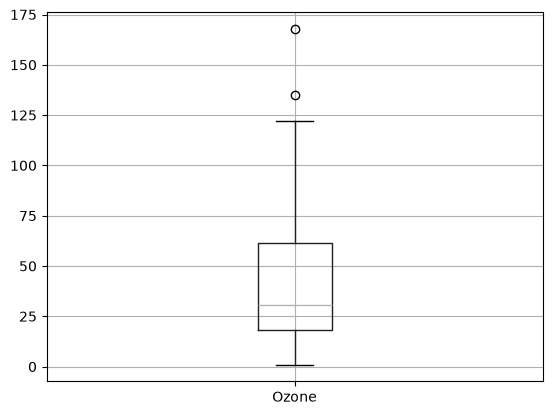

In [23]:
df.boxplot(column='Ozone')
plt.show()

In [24]:
df.describe()

,Ozone,Solar,Wind,Day,Year,Temp,Date
count,120.000000,158.000000,158.000000,158.000000,158.0,158.000000,158
mean,41.725000,187.321881,9.884177,16.044304,2025.0,77.613924,2025-07-17 00:45:34.177215
min,1.000000,7.000000,1.700000,1.000000,2025.0,56.000000,2025-05-01 00:00:00
25%,18.000000,131.000000,7.400000,8.250000,2025.0,72.000000,2025-06-07 06:00:00
50%,30.500000,193.000000,9.700000,16.000000,2025.0,78.000000,2025-07-15 12:00:00
75%,61.500000,255.750000,11.500000,24.000000,2025.0,84.000000,2025-08-26 18:00:00
max,168.000000,334.000000,20.700000,31.000000,2025.0,97.000000,2025-09-30 00:00:00
std,32.765775,85.731163,3.510685,8.990685,0.0,9.436158,NaN


In [25]:
IQR=61.500000-18.000000
max_limit=61.500000+1.5*IQR
max_limit

126.75

In [26]:
df[df['Ozone']>max_limit]

,Ozone,Solar,Wind,Month,Day,Year,Temp,Weather,Date
61,135.0,269.0,4.1,7,1,2025,84,S,2025-07-01
114,168.0,238.0,3.4,8,25,2025,81,PS,2025-08-25


## Univariate Analysis (Feature Understanding)

In [27]:
df.dtypes

Ozone             float64
Solar             float64
Wind              float64
Month                 str
Day                 int64
Year                int64
Temp                int64
Weather               str
Date       datetime64[us]
dtype: object

In [28]:
df['Weather'].unique()

<StringArray>
['S', 'C', 'PS']
Length: 3, dtype: str

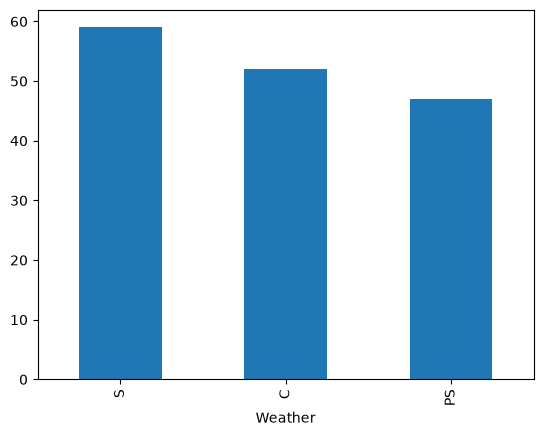

In [29]:
df['Weather'].value_counts().plot(kind='bar')
plt.show()

In [30]:
df.skew(numeric_only=True)

Ozone    1.286411
Solar   -0.449657
Wind     0.392470
Day     -0.034937
Year          NaN
Temp    -0.293318
dtype: float64

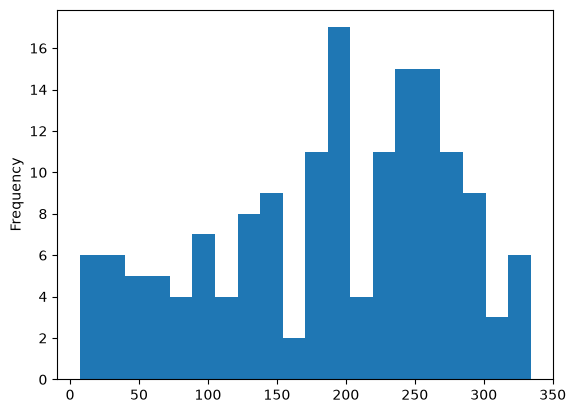

In [31]:
df['Solar'].plot(kind='hist', bins=20)
plt.show()

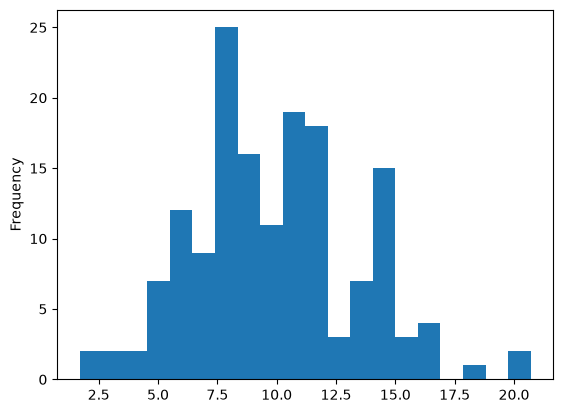

In [32]:
df['Wind'].plot(kind='hist', bins=20)
plt.show()

In [33]:
df.describe()

,Ozone,Solar,Wind,Day,Year,Temp,Date
count,120.000000,158.000000,158.000000,158.000000,158.0,158.000000,158
mean,41.725000,187.321881,9.884177,16.044304,2025.0,77.613924,2025-07-17 00:45:34.177215
min,1.000000,7.000000,1.700000,1.000000,2025.0,56.000000,2025-05-01 00:00:00
25%,18.000000,131.000000,7.400000,8.250000,2025.0,72.000000,2025-06-07 06:00:00
50%,30.500000,193.000000,9.700000,16.000000,2025.0,78.000000,2025-07-15 12:00:00
75%,61.500000,255.750000,11.500000,24.000000,2025.0,84.000000,2025-08-26 18:00:00
max,168.000000,334.000000,20.700000,31.000000,2025.0,97.000000,2025-09-30 00:00:00
std,32.765775,85.731163,3.510685,8.990685,0.0,9.436158,NaN


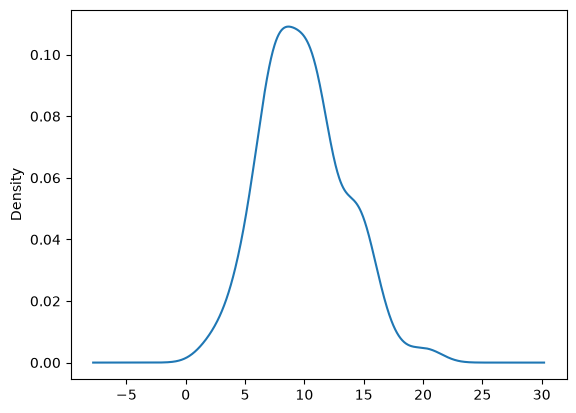

In [34]:
df['Wind'].plot(kind='kde')
plt.show()

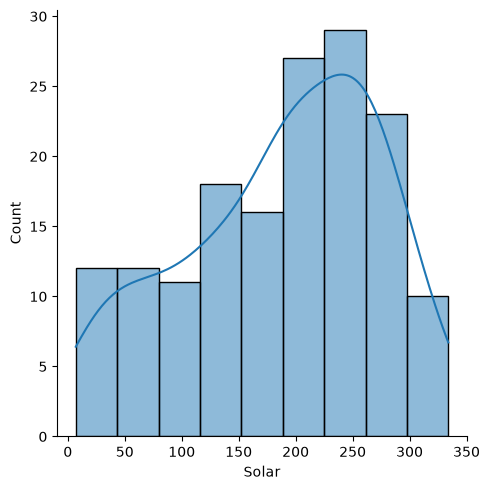

In [35]:
sns.displot(data=df, x='Solar', kind='hist', kde=True)
plt.show()

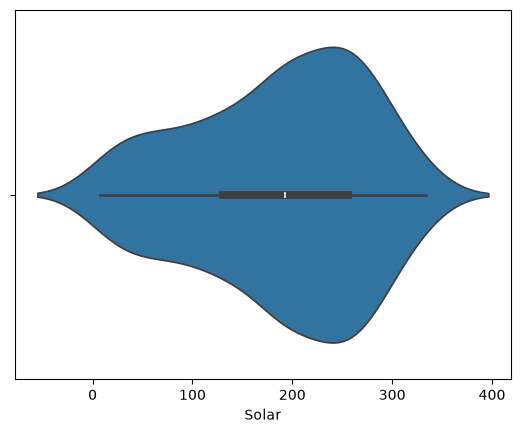

In [36]:
sns.violinplot(data=df, x='Solar')
plt.show()

## Bivariate and Multucariate Analysis (Feature Relationships)

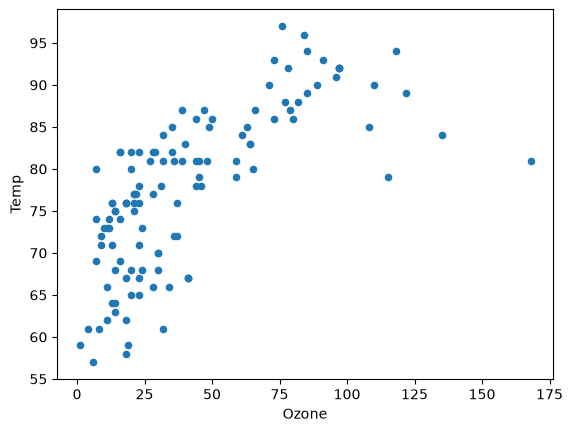

In [37]:
df.plot(kind='scatter', x='Ozone', y='Temp')
plt.show()

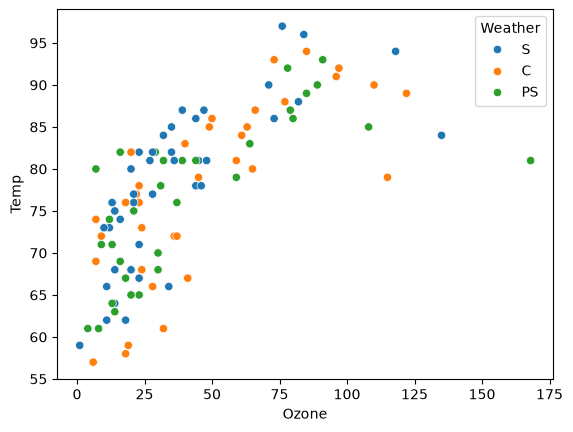

In [40]:
sns.scatterplot(data=df, x='Ozone', y='Temp', hue='Weather')
plt.show()

In [43]:
df1=df.drop(['Year'], axis=1)
df1

,Ozone,Solar,Wind,Month,Day,Temp,Weather,Date
0,41.0,190.000000,7.4,5,1,67,S,2025-05-01
1,36.0,118.000000,8.0,5,2,72,C,2025-05-02
2,12.0,149.000000,12.6,5,3,74,PS,2025-05-03
3,18.0,313.000000,11.5,5,4,62,S,2025-05-04
4,NaN,185.642857,14.3,5,5,56,S,2025-05-05
...,...,...,...,...,...,...,...,...
153,30.0,193.000000,6.9,9,26,70,PS,2025-09-26
154,NaN,145.000000,13.2,9,27,77,S,2025-09-27
155,14.0,191.000000,14.3,9,28,75,S,2025-09-28
156,18.0,131.000000,8.0,9,29,76,C,2025-09-29


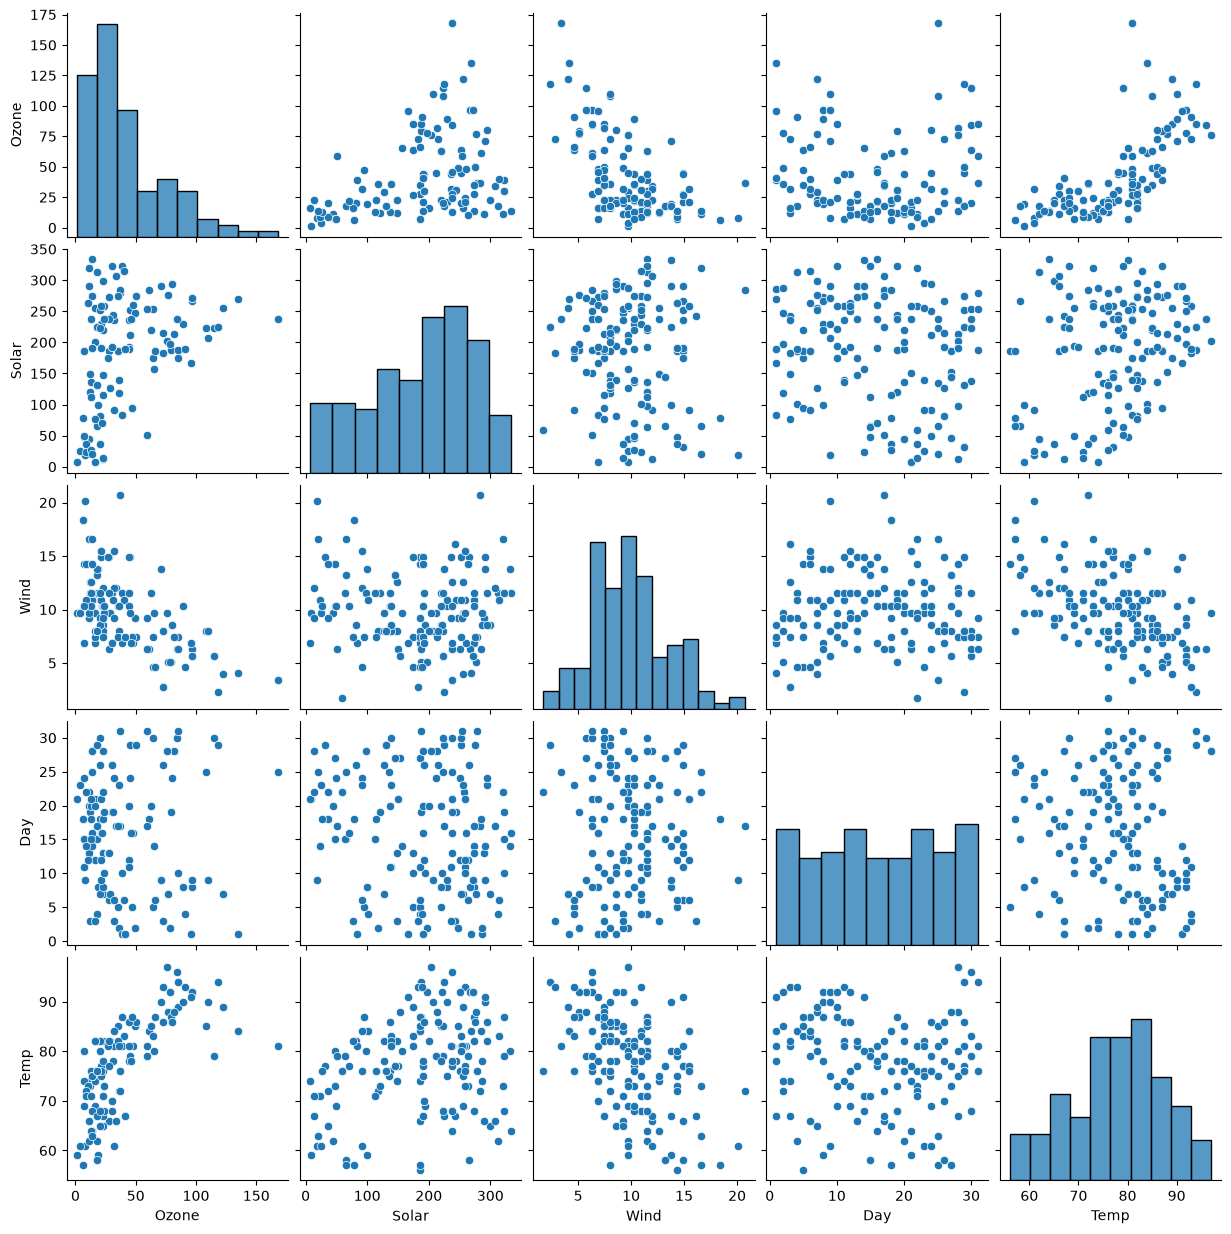

In [44]:
sns.pairplot(data=df1)
plt.show()

In [46]:
df1.corr(numeric_only=True)

,Ozone,Solar,Wind,Day,Temp
Ozone,1.000000,0.353076,-0.589411,-0.058406,0.700687
Solar,0.353076,1.000000,-0.043490,-0.172324,0.283028
Wind,-0.589411,-0.043490,1.000000,0.047828,-0.445408
Day,-0.058406,-0.172324,0.047828,1.000000,-0.116844
Temp,0.700687,0.283028,-0.445408,-0.116844,1.000000


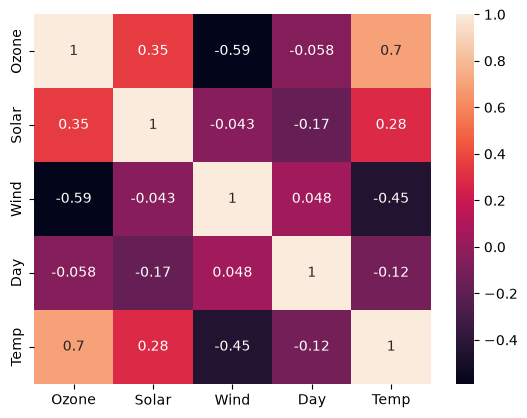

In [48]:
sns.heatmap(df1.corr(numeric_only=True), annot=True)
plt.show()

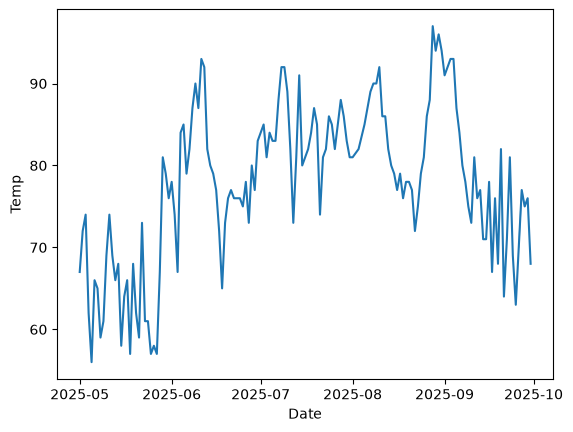

In [51]:
sns.lineplot(data=df, x='Date', y='Temp')
plt.show()

In [52]:
pd.crosstab(df['Month'], df['Weather'])

Weather,C,PS,S
Month,,,
5,12,9,12
6,9,9,12
7,12,8,11
8,10,8,11
9,9,13,13


In [54]:
df.groupby('Weather').mean(numeric_only=True)

,Ozone,Solar,Wind,Day,Year,Temp
Weather,,,,,,
C,46.600000,192.306319,9.625000,15.346154,2025.0,77.769231
PS,42.194444,174.588146,9.908511,16.042553,2025.0,76.872340
S,36.909091,193.072639,10.093220,16.661017,2025.0,78.067797
